In [6]:
from pathlib import Path
import shutil

ROOT = Path("..").resolve()                      # racine du repo (le notebook est dans notebooks/)
RAW  = ROOT / "data/raw"

# le zip VISH-DARIJA-TTS : trouvé automatiquement (change le chemin si tu l'as mis ailleurs)
ZIP = next(RAW.rglob("*.zip"), None)
assert ZIP is not None, "Zip introuvable dans data/raw : mets son chemin à la main"
print("ZIP :", ZIP)

# emplacement cible, celui que le manifest attend
OUT  = RAW / "vish_darija_tts" / "extracted"
META = OUT / "metadata"

# diagnostic (aucune suppression)
old = RAW / "extracted"
print("Ancienne extraction (data/raw/extracted)  :", old.exists())
print("Nouvel emplacement (vish_darija_tts/...)  :", OUT.exists())
free = shutil.disk_usage(ROOT).free / 1e9
print(f"Disque libre : {free:.1f} Go")

ZIP : C:\Users\chern\Desktop\vishing-detection-1\data\raw\VISH-DARIJA-TTS-v1.0.zip
Ancienne extraction (data/raw/extracted)  : False
Nouvel emplacement (vish_darija_tts/...)  : False
Disque libre : 7.3 Go


In [7]:
import zipfile
from collections import Counter
from pathlib import PurePosixPath

with zipfile.ZipFile(ZIP) as z:
    infos = z.infolist()

print("Nombre de fichiers :", len(infos))
print("Taille décompressée totale : %.1f Go" % (sum(i.file_size for i in infos) / 1e9))

# Extensions
print("\nExtensions :", Counter(PurePosixPath(i.filename).suffix.lower() for i in infos))

# Premiers niveaux de dossiers
print("\nDossiers principaux :")
print(Counter("/".join(PurePosixPath(i.filename).parts[:2]) for i in infos).most_common(20))

# Fichiers non audio (métadonnées, splits, docs)
print("\nFichiers non-WAV :")
for i in infos:
    if not i.filename.lower().endswith(".wav") and not i.is_dir():
        print(f"  {i.filename}  ({i.file_size / 1e6:.2f} Mo)")

Nombre de fichiers : 13709
Taille décompressée totale : 15.7 Go

Extensions : Counter({'.wav': 13610, '.csv': 41, '.md': 30, '.py': 16, '.json': 7, '.txt': 3, '.cff': 1, '': 1})

Dossiers principaux :
[('audio/noisy', 10200), ('audio/clean_normalized', 3400), ('audio/noise_sources', 10), ('CITATION.cff', 1), ('LICENSE', 1), ('README.md', 1), ('checksums_sha256.txt', 1), ('data/dialogues_normal_clean.json', 1), ('data/dialogues_normal_public.json', 1), ('data/dialogues_normal_raw.json', 1), ('data/dialogues_scam_clean.json', 1), ('data/dialogues_scam_public.json', 1), ('data/dialogues_scam_raw.json', 1), ('dataset_card.md', 1), ('ethics_statement.md', 1), ('metadata/attack_taxonomy.csv', 1), ('metadata/audio_json_link_report.csv', 1), ('metadata/audio_manifest.csv', 1), ('metadata/audio_manifest_normalized.csv', 1), ('metadata/audio_manifest_normalized_with_splits.csv', 1)]

Fichiers non-WAV :
  CITATION.cff  (0.00 Mo)
  LICENSE  (0.00 Mo)
  README.md  (0.01 Mo)
  checksums_sha256.txt  

In [8]:
import zipfile
from collections import defaultdict
from pathlib import PurePosixPath

sizes = defaultdict(int)
counts = defaultdict(int)

with zipfile.ZipFile(ZIP) as z:
    infos = z.infolist()
    for i in infos:
        if i.is_dir():
            continue
        top = "/".join(PurePosixPath(i.filename).parts[:2]) if i.filename.startswith("audio/") \
              else PurePosixPath(i.filename).parts[0]
        sizes[top] += i.file_size
        counts[top] += 1

print("Taille décompressée par dossier audio :")
for k in sorted(sizes):
    if k.startswith("audio"):
        print(f"  {k:30s} {counts[k]:6d} fichiers   {sizes[k]/1e9:6.2f} Go")

# Extraction de tout sauf les WAV bruités et propres
with zipfile.ZipFile(ZIP) as z:
    to_extract = [i for i in z.infolist()
                  if not i.is_dir() and not i.filename.startswith("audio/noisy/")
                  and not i.filename.startswith("audio/clean_normalized/")]
    for i in to_extract:
        z.extract(i, OUT)
print(f"\n{len(to_extract)} fichiers extraits dans {OUT.resolve()}")

Taille décompressée par dossier audio :
  audio/clean_normalized           3400 fichiers     3.91 Go
  audio/noise_sources                10 fichiers     0.06 Go
  audio/noisy                     10200 fichiers    11.72 Go

109 fichiers extraits dans C:\Users\chern\Desktop\vishing-detection-1\data\raw\vish_darija_tts\extracted


In [9]:
import zipfile
from collections import defaultdict
from pathlib import PurePosixPath

sizes = defaultdict(int)
counts = defaultdict(int)

with zipfile.ZipFile(ZIP) as z:
    infos = z.infolist()
    for i in infos:
        if i.is_dir():
            continue
        top = "/".join(PurePosixPath(i.filename).parts[:2]) if i.filename.startswith("audio/") \
              else PurePosixPath(i.filename).parts[0]
        sizes[top] += i.file_size
        counts[top] += 1

print("Taille décompressée par dossier audio :")
for k in sorted(sizes):
    if k.startswith("audio"):
        print(f"  {k:30s} {counts[k]:6d} fichiers   {sizes[k]/1e9:6.2f} Go")

# Extraction de tout sauf les WAV bruités et propres
with zipfile.ZipFile(ZIP) as z:
    to_extract = [i for i in z.infolist()
                  if not i.is_dir() and not i.filename.startswith("audio/noisy/")
                  and not i.filename.startswith("audio/clean_normalized/")]
    for i in to_extract:
        z.extract(i, OUT)
print(f"\n{len(to_extract)} fichiers extraits dans {OUT.resolve()}")

Taille décompressée par dossier audio :
  audio/clean_normalized           3400 fichiers     3.91 Go
  audio/noise_sources                10 fichiers     0.06 Go
  audio/noisy                     10200 fichiers    11.72 Go

109 fichiers extraits dans C:\Users\chern\Desktop\vishing-detection-1\data\raw\vish_darija_tts\extracted


In [10]:
import pandas as pd

for csv in sorted((OUT / "metadata").glob("*.csv")):
    df = pd.read_csv(csv, nrows=3)
    n = sum(1 for _ in open(csv, encoding="utf-8")) - 1
    print(f"\n{csv.name}  ({n} lignes)")
    print("  colonnes :", list(df.columns))


attack_taxonomy.csv  (72 lignes)
  colonnes : ['field', 'category', 'definition', 'examples']

audio_json_link_report.csv  (12 lignes)
  colonnes : ['check_type', 'label', 'scenario_id', 'audio_file', 'status', 'message']

audio_manifest.csv  (3400 lignes)
  colonnes : ['audio_id', 'scenario_id', 'label', 'filename', 'relative_path', 'duration_sec', 'sample_rate_hz', 'channels', 'sample_width_bytes', 'sample_width_bits', 'num_frames', 'file_size_bytes', 'sha256', 'json_match_status', 'audio_status', 'notes']

audio_manifest_normalized.csv  (3400 lignes)
  colonnes : ['audio_id', 'scenario_id', 'label', 'filename', 'relative_path', 'duration_sec', 'sample_rate_hz', 'channels', 'sample_width_bytes', 'sample_width_bits', 'num_frames', 'file_size_bytes', 'sha256', 'json_match_status', 'audio_status', 'notes']

audio_manifest_normalized_with_splits.csv  (3400 lignes)
  colonnes : ['audio_id', 'scenario_id', 'label', 'filename', 'relative_path', 'duration_sec', 'sample_rate_hz', 'channels',

In [11]:
import pandas as pd

META = OUT / "metadata"
man = pd.read_csv(META / "audio_manifest_normalized_with_splits.csv")

# --- 1. Volumétrie ---
print("Fichiers audio propres :", len(man))
print("Scénarios uniques      :", man["scenario_id"].nunique())
print("Durée totale           : %.1f h" % (man["duration_sec"].sum() / 3600))
print("Taille totale          : %.2f Go" % (man["file_size_bytes"].sum() / 1e9))

# --- 2. Labels et déséquilibre ---
print("\n--- Labels ---")
print(man["label"].value_counts())
print(man["label"].value_counts(normalize=True).round(3))

print("\n--- Label x split ---")
ct = pd.crosstab(man["split"], man["label"], margins=True)
print(ct)
print((pd.crosstab(man["split"], man["label"], normalize="index") * 100).round(1))

# --- 3. Durée par label (un biais de durée peut trahir le label) ---
print("\n--- Durée (s) par label ---")
print(man.groupby("label")["duration_sec"].describe().round(1))

# --- 4. Format audio ---
print("\n--- Format audio ---")
for col in ["sample_rate_hz", "channels", "sample_width_bits", "audio_status", "json_match_status"]:
    print(f"\n{col} :")
    print(man[col].value_counts(dropna=False))

# --- 5. Intégrité des données ---
print("\n--- Intégrité ---")
print("sha256 dupliqués       :", man["sha256"].duplicated().sum())
print("audio_id dupliqués     :", man["audio_id"].duplicated().sum())
print("Valeurs manquantes     :\n", man.isna().sum()[man.isna().sum() > 0])

# --- 6. Fuite de données : un scénario dans plusieurs splits ? ---
leak = man.groupby("scenario_id")["split"].nunique()
print("\nScénarios présents dans >1 split :", (leak > 1).sum())

Fichiers audio propres : 3400
Scénarios uniques      : 1700
Durée totale           : 22.6 h
Taille totale          : 3.91 Go

--- Labels ---
label
normal    1700
scam      1700
Name: count, dtype: int64
label
normal    0.5
scam      0.5
Name: proportion, dtype: float64

--- Label x split ---
label       normal  scam   All
split                         
test           255   255   510
train         1190  1190  2380
validation     255   255   510
All           1700  1700  3400
label       normal  scam
split                   
test          50.0  50.0
train         50.0  50.0
validation    50.0  50.0

--- Durée (s) par label ---
         count  mean   std  min   25%   50%   75%   max
label                                                  
normal  1700.0  17.6   2.8  6.9  15.7  17.6  19.3  28.6
scam    1700.0  30.3  14.6  8.1  20.1  24.9  38.3  77.5

--- Format audio ---

sample_rate_hz :
sample_rate_hz
24000    3400
Name: count, dtype: int64

channels :
channels
1    3400
Name: count, dtyp

In [12]:
# 1) Que contient dataset_uid ?
print(man[["audio_id", "scenario_id", "label", "dataset_uid", "split"]].head(6))
print("\ndataset_uid uniques :", man["dataset_uid"].nunique())

# 2) scenario_id est-il unique seulement à l'intérieur d'un label ?
print("\n(scenario_id, label) uniques :", man[["scenario_id", "label"]].drop_duplicates().shape[0])
print("Scénarios présents dans les 2 labels :",
      (man.groupby("scenario_id")["label"].nunique() > 1).sum())

# 3) Fuite réelle : identifiant complet (label + scenario_id) dans >1 split ?
leak_real = man.groupby("dataset_uid")["split"].nunique()
print("\nVraie fuite (dataset_uid dans >1 split) :", (leak_real > 1).sum())

# 4) Les 774 : sont-ils des paires normal/scam séparées ?
multi = leak[leak > 1].index
sub = man[man["scenario_id"].isin(multi)]
print("Parmi les 774, répartition des labels :")
print(sub.groupby("scenario_id")["label"].nunique().value_counts())

      audio_id  scenario_id   label  dataset_uid       split
0  normal_0103          103  normal  normal_0103       train
1  normal_1000         1000  normal  normal_1000  validation
2  normal_1001         1001  normal  normal_1001       train
3  normal_1002         1002  normal  normal_1002       train
4  normal_1003         1003  normal  normal_1003       train
5  normal_1004         1004  normal  normal_1004        test

dataset_uid uniques : 3400

(scenario_id, label) uniques : 3400
Scénarios présents dans les 2 labels : 1700

Vraie fuite (dataset_uid dans >1 split) : 0
Parmi les 774, répartition des labels :
label
2    774
Name: count, dtype: int64


In [13]:
for col in ["sample_rate_hz", "channels", "sample_width_bits", "audio_status", "json_match_status"]:
    print(col, man[col].value_counts(dropna=False).to_dict())
print("sha256 dupliqués :", man["sha256"].duplicated().sum(),
      "| audio_id dupliqués :", man["audio_id"].duplicated().sum())
print(man.groupby("label")["duration_sec"].describe().round(1))

sample_rate_hz {24000: 3400}
channels {1: 3400}
sample_width_bits {16: 3400}
audio_status {'readable': 3400}
json_match_status {'matched': 3400}
sha256 dupliqués : 0 | audio_id dupliqués : 0
         count  mean   std  min   25%   50%   75%   max
label                                                  
normal  1700.0  17.6   2.8  6.9  15.7  17.6  19.3  28.6
scam    1700.0  30.3  14.6  8.1  20.1  24.9  38.3  77.5


AUC avec la durée seule : 0.836
Seuil optimal sur train : 21 s (acc train 0.796)
Accuracy de cette règle sur test : 0.806
Scams plus longs que le plus long normal : 36.5%


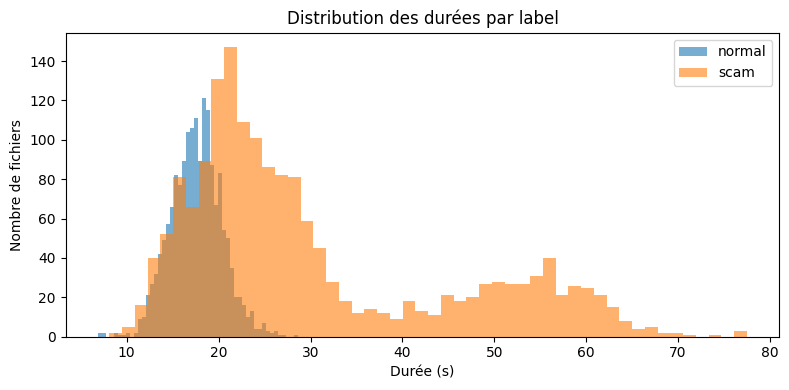

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

man["y"] = (man["label"] == "scam").astype(int)

# 1) AUC de la durée seule (0.5 = hasard, 1.0 = séparation parfaite)
auc = roc_auc_score(man["y"], man["duration_sec"])
print(f"AUC avec la durée seule : {auc:.3f}")

# 2) Règle triviale : seuil sur la durée, évaluée sur le split test
train = man[man["split"] == "train"]
test = man[man["split"] == "test"]
best_t, best_acc = None, 0
for t in range(10, 40):
    acc = ((train["duration_sec"] > t).astype(int) == train["y"]).mean()
    if acc > best_acc:
        best_t, best_acc = t, acc
test_acc = ((test["duration_sec"] > best_t).astype(int) == test["y"]).mean()
print(f"Seuil optimal sur train : {best_t} s (acc train {best_acc:.3f})")
print(f"Accuracy de cette règle sur test : {test_acc:.3f}")

# 3) Part des scams dépassant le max des normaux
print("Scams plus longs que le plus long normal :",
      f"{(man[man.y==1].duration_sec > man[man.y==0].duration_sec.max()).mean():.1%}")

# 4) Histogramme
fig, ax = plt.subplots(figsize=(8, 4))
for lab, g in man.groupby("label"):
    ax.hist(g["duration_sec"], bins=50, alpha=0.6, label=lab)
ax.set_xlabel("Durée (s)"); ax.set_ylabel("Nombre de fichiers"); ax.legend()
ax.set_title("Distribution des durées par label")
plt.tight_layout()
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/duration_by_label.png", dpi=150)
plt.show()

In [15]:
import re

turns = pd.read_csv(META / "turns_metadata_emotion_normalized_with_splits.csv")
print("Tours :", len(turns), "| dataset_uid uniques :", turns["dataset_uid"].nunique())

# --- 1. Tours par scénario, par label ---
tpc = turns.groupby(["dataset_uid", "label"]).size().rename("n_turns").reset_index()
print("\nTours par scénario :")
print(tpc.groupby("label")["n_turns"].describe().round(1))

# Lien durée <-> nombre de tours
m = man.merge(tpc[["dataset_uid", "n_turns"]], on="dataset_uid", how="left")
print("\nCorrélation durée / nb de tours :", round(m["duration_sec"].corr(m["n_turns"]), 3))
print("Scénarios audio sans tours :", m["n_turns"].isna().sum())

# --- 2. Rôles, genre, émotions ---
for col in ["speaker_role", "gender", "emotion_normalized", "annotation_status"]:
    print(f"\n{col} par label (%) :")
    print((pd.crosstab(turns[col], turns["label"], normalize="columns") * 100).round(1))

# --- 3. Demande sensible et type de demande ---
print("\ncontains_sensitive_request par label :")
print(pd.crosstab(turns["contains_sensitive_request"], turns["label"]))
print("\nrequest_type par label :")
print(pd.crosstab(turns["request_type"].fillna("(vide)"), turns["label"]))

# --- 4. Écritures : latin vs arabe ---
ar = re.compile(r"[\u0600-\u06FF]")
la = re.compile(r"[A-Za-z]")
turns["ar_chars"] = turns["text_arabic"].fillna("").map(lambda s: len(ar.findall(s)))
turns["la_chars"] = turns["text_latin"].fillna("").map(lambda s: len(la.findall(s)))
print("\ntext_arabic vide :", turns["text_arabic"].isna().sum(),
      "| sans caractère arabe :", (turns["ar_chars"] == 0).sum())
print("text_latin vide  :", turns["text_latin"].isna().sum(),
      "| sans caractère latin :", (turns["la_chars"] == 0).sum())

# --- 5. Texte corrompu signalé par les auteurs ---
cq = pd.read_csv(META / "corrupted_text_review_queue.csv")
print("\nFile de revue du texte corrompu :", len(cq), "lignes")
for col in ["field", "recommended_action", "status", "file"]:
    print(f"\n{col} :")
    print(cq[col].value_counts().head(8))
print("Scénarios touchés :", cq["scenario_id"].nunique())

Tours : 17351 | dataset_uid uniques : 3400

Tours par scénario :
         count  mean  std  min  25%  50%  75%   max
label                                              
normal  1700.0   4.0  0.1  4.0  4.0  4.0  4.0   5.0
scam    1700.0   6.2  2.3  2.0  5.0  5.0  8.0  11.0

Corrélation durée / nb de tours : 0.941
Scénarios audio sans tours : 0

speaker_role par label (%) :
label           normal  scam
speaker_role                
likely_scammer     0.0  53.7
likely_target      0.0  45.7
participant      100.0   0.0
unknown            0.0   0.6

gender par label (%) :
label    normal  scam
gender               
female      3.8   7.8
male       42.7  72.4
unknown    53.6  19.8

emotion_normalized par label (%) :
label               normal  scam
emotion_normalized              
angry                  0.5   1.5
anxious                3.0  10.3
authoritative          2.9  12.8
confused               0.3   3.1
distressed             0.0   4.1
fearful                0.0   2.9
friendly         

In [16]:
# --- 1. Nombre de tours seul : quelle baseline ? ---
m["y"] = (m["label"] == "scam").astype(int)
print("AUC n_turns seul :", round(roc_auc_score(m["y"], m["n_turns"]), 3))
for s in ["train", "test"]:
    d = m[m.split == s]
    print(f"Règle 'n_turns > 4 = scam' sur {s} : acc = {((d.n_turns > 4).astype(int) == d.y).mean():.3f}")

# --- 2. Zone de recouvrement : normal vs scam à 4 tours exactement ---
sub = m[m.n_turns == 4]
print("\nScénarios à 4 tours :", sub["label"].value_counts().to_dict())
if sub["label"].nunique() == 2:
    print("AUC de la durée à nb de tours égal :", round(roc_auc_score(sub["y"], sub["duration_sec"]), 3))
    print(sub.groupby("label")["duration_sec"].describe().round(1))

# --- 3. Demande sensible / type de demande (compact) ---
print("\ncontains_sensitive_request par label :")
print(pd.crosstab(turns["contains_sensitive_request"], turns["label"]))
print("\nrequest_type par label (top) :")
print(pd.crosstab(turns["request_type"].fillna("(vide)"), turns["label"]).sort_values("scam", ascending=False).head(10))

# --- 4. Écritures ---
print("\nSans caractère arabe :", (turns["ar_chars"] == 0).sum(),
      "| sans caractère latin :", (turns["la_chars"] == 0).sum(),
      "| texte arabe vide :", turns["text_arabic"].isna().sum(),
      "| texte latin vide :", turns["text_latin"].isna().sum())

# --- 5. Texte corrompu : l'essentiel ---
cq["label"] = cq["file"].str.contains("scam").map({True: "scam", False: "normal"})
for col in ["field", "recommended_action", "status"]:
    print(f"\n{col} :")
    print(cq[col].value_counts().head(8))

units = cq.drop_duplicates(["label", "scenario_id"]).groupby("label").size()
print("\nScénarios touchés (clé label + scenario_id) :", units.to_dict(), "sur 1700 par classe")
print("\nExemples :")
print(cq[["label", "field", "text_with_corruption", "recommended_action"]].head(5).to_string())

AUC n_turns seul : 0.851
Règle 'n_turns > 4 = scam' sur train : acc = 0.870
Règle 'n_turns > 4 = scam' sur test : acc = 0.867

Scénarios à 4 tours : {'normal': 1678, 'scam': 347}
AUC de la durée à nb de tours égal : 0.517
         count  mean  std   min   25%   50%   75%   max
label                                                  
normal  1678.0  17.5  2.7   6.9  15.7  17.6  19.2  28.6
scam     347.0  17.8  3.2  10.0  15.5  17.8  19.9  29.0

contains_sensitive_request par label :
label                       normal  scam
contains_sensitive_request              
no                            6822  7796
yes                              0  2733

request_type par label (top) :
label                 normal  scam
request_type                      
none                    6822  7796
money                      0  1064
bank_transfer              0   882
otp_code                   0   339
bank_card                  0   283
account_access             0   100
personal_information       0    28
pas

In [17]:
key = ["label", "scenario_id", "turn_index"]

# --- 1. Demande sensible au niveau scénario (et non plus au niveau tour) ---
sc = turns.groupby(["dataset_uid", "label"]).agg(
    n_sensitive=("contains_sensitive_request", lambda s: (s == "yes").sum())
).reset_index()
sc["any_sensitive"] = sc["n_sensitive"] > 0
print("Scénarios avec au moins une demande sensible :")
print(sc.groupby("label")["any_sensitive"].agg(["sum", "mean"]).round(3))

# Scams "difficiles" : 4 tours ET aucune demande sensible
hard = m.merge(sc[["dataset_uid", "any_sensitive"]], on="dataset_uid")
print("\nScams à 4 tours, avec / sans demande sensible :")
print(hard[(hard.label == "scam") & (hard.n_turns == 4)]["any_sensitive"].value_counts())

print("\nrequest_type complet :")
print(pd.crosstab(turns["request_type"], turns["label"]).sort_values("scam", ascending=False))

# --- 2. Corruption : ampleur réelle ---
cq["label"] = cq["file"].str.contains("scam").map({True: "scam", False: "normal"})
for col in ["field", "recommended_action", "status"]:
    print(f"\n{col} :")
    print(cq[col].value_counts().head(6))

flagged = cq.drop_duplicates(key).groupby("label").size()
total = turns.groupby("label").size()
print("\nPart des tours signalés :")
print(pd.DataFrame({"signalés": flagged, "total": total, "part": (flagged / total).round(3)}))

# --- 3. Les deux textes d'un même tour corrompu ---
ex = cq.head(4).merge(turns[key + ["text_latin", "text_arabic"]], on=key, how="left")
print("\nExemples :")
print(ex[["label", "field", "text_with_corruption", "text_arabic"]].to_string())

Scénarios avec au moins une demande sensible :
         sum   mean
label              
normal     0  0.000
scam    1282  0.754

Scams à 4 tours, avec / sans demande sensible :
any_sensitive
False    178
True     169
Name: count, dtype: int64

request_type complet :
label                 normal  scam
request_type                      
none                    6822  7796
money                      0  1064
bank_transfer              0   882
otp_code                   0   339
bank_card                  0   283
account_access             0   100
personal_information       0    28
password                   0    27
location_or_meeting        0     6
other                      0     4

field :
field
t       6873
t_ar    2511
Name: count, dtype: int64

recommended_action :
recommended_action
manual text restoration required; do not guess    9384
Name: count, dtype: int64

status :
status
needs_manual_review    9384
Name: count, dtype: int64

Part des tours signalés :
        signalés  total   p

In [18]:
import collections, json, unicodedata

# 0) Liste complète des CSV (elle avait été tronquée)
print(sorted(p.name for p in META.glob("*.csv")))

# 1) Compteurs essentiels (sans afficher de lignes)
print("\nlignes :", len(cq))
for col in ["field", "recommended_action", "status"]:
    print(col, ":", cq[col].value_counts().head(6).to_dict())

flagged = cq.drop_duplicates(key).groupby("label").size()
total = turns.groupby("label").size()
print(pd.DataFrame({"tours_signalés": flagged, "tours_total": total,
                    "part": (flagged / total).round(3)}))
print("lignes par tour signalé :", cq.groupby(key).size().value_counts().to_dict())

# 2) Quels caractères inhabituels dans le texte signalé ?
cnt = collections.Counter(
    c for s in cq["text_with_corruption"].astype(str) for c in s
    if not (c.isascii() and (c.isalnum() or c in " .,!?'-"))
)
print("\nCaractères inhabituels dans text_with_corruption :")
for c, n in cnt.most_common(12):
    print(f"  {c!r:8} U+{ord(c):04X}  {unicodedata.name(c, '?'):35s} {n}")

# 3) Tatweel dans les textes arabes du corpus
tat = turns["text_arabic"].fillna("").str.contains("\u0640")
print("\nTours arabes avec tatweel :", tat.sum(), "sur", len(turns))

# 4) Un enregistrement brut, pour voir où se trouve la clé « t »
r = cq.iloc[0]
data = json.load(open(OUT / "data" / r["file"], encoding="utf-8"))
first = data[0] if isinstance(data, list) else data
print("\nFichier :", r["file"], "| type :", type(data).__name__)
print("Clés du premier élément :", list(first.keys())[:10])

['attack_taxonomy.csv', 'audio_json_link_report.csv', 'audio_manifest.csv', 'audio_manifest_normalized.csv', 'audio_manifest_normalized_with_splits.csv', 'audio_normalization_report.csv', 'corrupted_text_review_queue.csv', 'critical_ids_diagnosis.csv', 'critical_ids_fix_report.csv', 'data_dictionary.csv', 'doi_update_report.csv', 'emotion_mapping_report.csv', 'emotion_taxonomy.csv', 'final_release_file_counts.csv', 'final_release_validation_report.csv', 'generation_log.csv', 'json_audit_report.csv', 'json_cleaning_report.csv', 'metadata_build_report.csv', 'missing_t_ar_injection_report.csv', 'missing_t_ar_review_template.csv', 'noise_mixing_report.csv', 'noise_mixing_report_test.csv', 'noise_sources_metadata.csv', 'noisy_audio_manifest.csv', 'noisy_audio_manifest_test.csv', 'noisy_audio_manifest_with_splits.csv', 'path_sanitization_report.csv', 'post_doi_cleanup_report.csv', 'private_key_scan_resolution_report.csv', 'release_cleanup_exclusions_report.csv', 'release_layers.csv', 'reposi

In [19]:
import json, re

def load_json(name):
    return json.load(open(OUT / "data" / name, encoding="utf-8"))

def num(x):                       # "normal_0103" -> 103
    return int(re.findall(r"\d+", str(x))[-1])

clean = {num(d["id"]): d for d in load_json("dialogues_normal_clean.json")}
raw   = {num(d["id"]): d for d in load_json("dialogues_normal_raw.json")}

# 1) Structure d'un dialogue
d0 = clean[min(clean)]
print("Clés d'un tour :", list(d0["dialogue"][0].keys()), "| theme :", d0["theme"])
print("turn_index min/max dans les CSV :", turns["turn_index"].min(), turns["turn_index"].max())

# 2) Texte signalé : clean vs raw (corpus normal, champ t)
diff = same = 0
for _, r in cq[(cq.label == "normal") & (cq.field == "t")].iterrows():
    sid, ti = num(r.scenario_id), int(r.turn_index)
    try:
        a, b = clean[sid]["dialogue"][ti]["t"], raw[sid]["dialogue"][ti]["t"]
    except Exception:
        continue
    diff += a != b
    same += a == b
print(f"\nnormal/t signalés : clean ≠ raw : {diff} | identiques : {same}")

# 3) Hypothèse : le détecteur réagit aux tirets / chiffres du darija latin
flag = set(zip(cq["label"], cq["scenario_id"], cq["turn_index"]))
turns["flagged"] = [(l, s, t) in flag for l, s, t in
                    zip(turns["label"], turns["scenario_id"], turns["turn_index"])]
lat = turns["text_latin"].fillna("")
turns["has_hyphen"] = lat.str.contains("-")
turns["has_digit"] = lat.str.contains(r"\d")

for col in ["has_hyphen", "has_digit"]:
    print(f"\nPart de tours signalés selon {col} :")
    print(turns.groupby(["label", col])["flagged"].agg(["mean", "size"]).round(3).to_string())

Clés d'un tour : ['s', 'e', 't', 't_ar', 'gender'] | theme : Asking a friend about a shared project
turn_index min/max dans les CSV : 0 10

normal/t signalés : clean ≠ raw : 0 | identiques : 3932

Part de tours signalés selon has_hyphen :
                    mean  size
label  has_hyphen             
normal False       0.634  1032
       True        0.566  5790
scam   False       0.286  9523
       True        0.214  1006

Part de tours signalés selon has_digit :
                   mean  size
label  has_digit             
normal False      0.731  2423
       True       0.491  4399
scam   False      0.277  3432
       True       0.280  7097


In [20]:
# --- 1. Métadonnées de scénario : langues, thèmes... (colonnes catégorielles) ---
sm = pd.read_csv(META / "scenarios_metadata_with_splits.csv")
print("Colonnes scénarios :", list(sm.columns), "| lignes :", len(sm))
if "label" in sm.columns:
    for col in sm.columns:
        if col in ("label", "split"):
            continue
        n = sm[col].nunique()
        if 1 < n <= 12:
            print(f"\n{col} ({n} valeurs) par label :")
            print(pd.crosstab(sm[col].fillna("(vide)"), sm["label"]).to_string())

# --- 2. Variantes bruitées : équilibre, SNR, fuite entre splits ---
nz = pd.read_csv(META / "noisy_audio_manifest_with_splits.csv")
print("\nColonnes bruité :", list(nz.columns), "| lignes :", len(nz))
snr = next((c for c in nz.columns if "snr" in c.lower()), None)
if snr and {"split", "label"} <= set(nz.columns):
    print(pd.crosstab([nz["split"], nz["label"]], nz[snr]).to_string())
if "dataset_uid" in nz.columns:
    ref = man.set_index("dataset_uid")["split"]
    print("Bruités dont le split ≠ split du propre :", (nz["dataset_uid"].map(ref) != nz["split"]).sum())
    print("Variantes par dataset_uid :", nz.groupby("dataset_uid").size().value_counts().to_dict())

# --- 3. Journal de génération : voix TTS, moteur, paramètres ---
gl = pd.read_csv(META / "generation_log.csv")
print("\nColonnes generation_log :", list(gl.columns), "| lignes :", len(gl))
for col in gl.columns:
    if 1 < gl[col].nunique() <= 8:
        print(col, gl[col].value_counts().to_dict())

Colonnes scénarios : ['scenario_id', 'label', 'theme', 'num_turns', 'has_audio', 'audio_id', 'audio_path', 'duration_sec', 'split', 'attack_type', 'persuasion_strategy', 'requested_asset', 'impersonated_entity', 'victim_role', 'risk_level', 'annotation_status', 'dataset_uid'] | lignes : 3400

num_turns (10 valeurs) par label :
label      normal  scam
num_turns              
2               0     4
3               0    69
4            1678   347
5              22   608
6               0    30
7               0   205
8               0    56
9               0     4
10              0   360
11              0    17

persuasion_strategy (12 valeurs) par label :
label                normal  scam
persuasion_strategy              
authority                 0   183
empathy                   0    66
fear                      0     7
intimidation              0    30
none                   1700     0
opportunity               0     1
other                     0    51
religious_trust           0    

In [21]:
# --- 1. Journal de génération : colonnes utiles, constantes comprises ---
print(gl[["label", "tts_provider", "tts_model", "language_code", "status"]].drop_duplicates().to_string())

# --- 2. Variantes bruitées : même split que le fichier propre ? ---
ref = man.set_index("dataset_uid")["split"]
print("\nColonnes bruité :", list(nz.columns))
print("Bruités avec split ≠ split du propre :",
      int((nz["dataset_uid"].map(ref) != nz["split"]).sum()), "sur", len(nz))

# --- 3. Qu'est-ce qui déclenche le signalement ? ---
print("\nPart signalée par genre :")
print(turns.groupby(["label", "gender"])["flagged"].agg(["mean", "size"]).round(3).to_string())

print("\nPart signalée par position du tour :")
print(turns.groupby(["label", "turn_index"])["flagged"].mean().unstack(0).round(2).to_string())

sf = turns.groupby(["label", "dataset_uid"])["flagged"].mean().reset_index()
sf["couverture"] = pd.cut(sf["flagged"], [-0.01, 0, 0.99, 1],
                          labels=["aucun tour", "partiel", "tous les tours"])
print("\nScénarios par couverture du signalement :")
print(sf.groupby(["label", "couverture"], observed=True).size().unstack().to_string())

# --- 4. Ce que dit l'auteur ---
for name in ["json_cleaning_report.csv", "missing_t_ar_injection_report.csv",
             "final_release_validation_report.csv"]:
    r = pd.read_csv(META / name)
    print(f"\n{name} : {len(r)} lignes | colonnes : {list(r.columns)}")
    print(r.head(4).to_string(max_colwidth=60))

    label  tts_provider                     tts_model language_code   status
0  normal  google_genai  gemini-3.1-flash-tts-preview         ar-EG  success
5    scam  google_genai  gemini-3.1-flash-tts-preview         ar-EG  success

Colonnes bruité : ['noisy_audio_id', 'clean_audio_id', 'scenario_id', 'label', 'snr_db', 'noisy_audio_path', 'clean_audio_path', 'noise_id', 'noise_filename', 'noise_category', 'duration_sec', 'sample_rate_hz', 'channels', 'sample_width_bytes', 'sample_width_bits', 'file_size_bytes', 'sha256', 'status', 'notes', 'dataset_uid', 'split']
Bruités avec split ≠ split du propre : 0 sur 10200

Part signalée par genre :
                 mean  size
label  gender              
normal female   0.895   256
       male     0.633  2910
       unknown  0.509  3656
scam   female   0.503   819
       male     0.256  7623
       unknown  0.275  2087

Part signalée par position du tour :
label       normal  scam
turn_index              
0             0.92  0.21
1             0

In [22]:
import re

# --- 1. Couverture du signalement par scénario ---
sf = turns.groupby(["label", "dataset_uid"])["flagged"].mean().reset_index()
sf["couverture"] = pd.cut(sf["flagged"], [-0.01, 0, 0.99, 1],
                          labels=["aucun tour", "partiel", "tous les tours"])
print(sf.groupby(["label", "couverture"], observed=True).size().unstack().to_string())

# --- 2. Rapports de l'auteur : résumé des colonnes catégorielles ---
for name in ["json_cleaning_report.csv", "missing_t_ar_injection_report.csv"]:
    r = pd.read_csv(META / name)
    print(f"\n{name} : {len(r)} lignes | colonnes : {list(r.columns)}")
    for col in r.columns:
        if 1 <= r[col].nunique(dropna=False) <= 6:
            print(f"  {col} : {r[col].value_counts(dropna=False).to_dict()}")

# --- 3. Sécurité : contrôles non réussis et résolution ---
v = pd.read_csv(META / "final_release_validation_report.csv")
stcol = next(c for c in v.columns if v[c].astype(str).isin(["passed", "failed"]).any())
print("\nContrôles de validation :", v[stcol].value_counts().to_dict())
print(v[v[stcol] != "passed"].to_string(max_colwidth=90))

res = pd.read_csv(META / "private_key_scan_resolution_report.csv")
print("\nprivate_key_scan_resolution_report :")
print(res.head(10).to_string(max_colwidth=90))

# --- 4. Scan local : ce fichier contient-il encore une clé ? (affiche seulement le chemin) ---
pat = re.compile(r"BEGIN [A-Z ]*PRIVATE KEY|\"private_key\"\s*:\s*\"[^\"]+")
print("\nFichiers à vérifier :")
for p in OUT.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".json", ".py", ".txt", ".md", ".csv", ".cff", ""}:
        if pat.search(p.read_text(encoding="utf-8", errors="ignore")):
            print("  ", p.relative_to(OUT))

# --- 5. Bruit : SNR et catégories de bruit par classe ---
print("\nVariantes par label et SNR :")
print(pd.crosstab(nz["label"], nz["snr_db"]).to_string())
print("\nCatégories de bruit par label :")
print(pd.crosstab(nz["noise_category"], nz["label"]).to_string())

couverture  aucun tour  partiel  tous les tours
label                                          
normal            23.0   1673.0             4.0
scam             686.0   1014.0             NaN

json_cleaning_report.csv : 9424 lignes | colonnes : ['file', 'scenario_id', 'turn_index', 'issue_type', 'field', 'old_value', 'new_value', 'action', 'status', 'severity']
  file : {'dialogues_scam_clean.json': 5486, 'dialogues_normal_clean.json': 3938}
  field : {'t': 6873, 't_ar': 2517, 'is_scam': 16, 'gender': 10, 'dialog_e': 6, ' Ferguson': 2}
  old_value : {'contains_?': 9384, 'missing': 16, 'inconsistent': 8, 'False': 8, 'present': 6, 'Professional': 2}
  action : {'queued_for_manual_review': 9384, 'needs_manual_review': 16, 'precheck_detected': 12, 'set_expected_label': 8, 'renamed_dialog_e_to_dialogue': 3, 'renamed_ferguson_to_e': 1}
  status : {'not_fixed': 9400, 'logged': 12, 'fixed': 12}
  severity : {'major': 9392, 'critical': 32}

missing_t_ar_injection_report.csv : 6 lignes | colonne

In [23]:
from scipy.stats import chi2_contingency

# --- 1. Le signalement = présence d'un "?" ? ---
q = lambda c: turns[c].fillna("").str.contains(r"\?", regex=True)
turns["has_q"] = q("text_latin") | q("text_arabic")
print(turns.groupby(["label", "has_q"])["flagged"].agg(["mean", "size"]).round(3).to_string())

txt = cq["text_with_corruption"].astype(str)
print("\nLignes signalées avec '?' :", round((txt.str.count(r"\?") > 0).mean(), 3))
print("Lignes avec '??' consécutifs (perte d'encodage probable) :", int(txt.str.contains(r"\?\?").sum()))

# --- 2. Les 6 textes arabes injectés : '?' dans le CSV de rapport seulement, ou dans les données ? ---
inj = pd.read_csv(META / "missing_t_ar_injection_report.csv")
chk = inj[["scenario_id", "turn_index"]].merge(
    turns[turns.label == "scam"][["scenario_id", "turn_index", "text_arabic"]],
    on=["scenario_id", "turn_index"], how="left")
chk["n_q"] = chk["text_arabic"].fillna("").str.count(r"\?")
chk["longueur"] = chk["text_arabic"].fillna("").str.len()
print("\n", chk[["scenario_id", "turn_index", "n_q", "longueur"]].to_string())

# --- 3. Labels des JSON vs fichier d'origine ---
for name in ["dialogues_scam_clean.json", "dialogues_normal_clean.json"]:
    d = load_json(name)
    print(name, len(d), pd.Series([x.get("is_scam") for x in d]).value_counts(dropna=False).to_dict())

# --- 4. Bruit : SNR et catégories indépendants du label ? ---
print("\n", pd.crosstab(nz["label"], nz["snr_db"]).to_string())
ct = pd.crosstab(nz["noise_category"], nz["label"])
print("\nCatégories de bruit : chi2 p-value =", round(chi2_contingency(ct)[1], 3))

# --- 5. Sécurité : contrôle en échec et sa résolution (chemins seulement, pas de contenu) ---
v = pd.read_csv(META / "final_release_validation_report.csv")
print("\n", v[v.eq("failed").any(axis=1)].to_string(max_colwidth=70))
res = pd.read_csv(META / "private_key_scan_resolution_report.csv")
print("\n", res.to_string(max_colwidth=70))

pat = re.compile(r"BEGIN [A-Z ]*PRIVATE KEY|\"private_key\"\s*:\s*\"[^\"]+")
print("\nFichiers hors scripts qui contiennent encore le motif :")
for p in OUT.rglob("*"):
    if p.is_file() and "scripts" not in p.parts and p.suffix.lower() in {".json", ".txt", ".md", ".csv", ".cff"}:
        if pat.search(p.read_text(encoding="utf-8", errors="ignore")):
            print("  ", p.relative_to(OUT))

               mean  size
label  has_q             
normal False  0.000  2890
       True   1.000  3932
scam   False  0.000  7582
       True   0.998  2947

Lignes signalées avec '?' : 1.0
Lignes avec '??' consécutifs (perte d'encodage probable) : 0

    scenario_id  turn_index  n_q  longueur
0          324           0   61        73
1          324           1   48        58
2          324           2   62        74
3          333           0   55        65
4          333           1   30        38
5          333           2   53        63
dialogues_scam_clean.json 1700 {True: 1700}
dialogues_normal_clean.json 1700 {False: 1700}

 snr_db  5.0   10.0  20.0
label                   
normal  1700  1700  1700
scam    1700  1700  1700

Catégories de bruit : chi2 p-value = 0.789

   check_category              check_name  status  severity                                                             message  count                                notes
1       security  private_key_token_scan  fa

In [24]:
import io, wave
import numpy as np
from pathlib import PurePosixPath

samp = man.groupby("label", group_keys=False).sample(150, random_state=42)
rows = []
with zipfile.ZipFile(ZIP) as z:
    index = {PurePosixPath(n).name: n for n in z.namelist() if n.startswith("audio/clean_normalized/")}
    for r in samp.itertuples():
        name = index.get(r.filename)
        if name is None:
            rows.append({"audio_id": r.audio_id, "label": r.label, "missing": True})
            continue
        with wave.open(io.BytesIO(z.read(name))) as w:
            sr, ch, sw, nf = w.getframerate(), w.getnchannels(), w.getsampwidth(), w.getnframes()
            x = np.frombuffer(w.readframes(nf), dtype="<i2").astype(np.float32) / 32768
        frame = int(0.025 * sr)
        fr = x[: len(x) // frame * frame].reshape(-1, frame)
        fr_rms = np.sqrt((fr ** 2).mean(axis=1) + 1e-12)
        rows.append({
            "audio_id": r.audio_id, "label": r.label, "missing": False,
            "sr": sr, "ch": ch, "sw": sw,
            "duration_diff": abs(nf / sr - r.duration_sec),
            "peak": float(np.abs(x).max()),
            "rms_db": 20 * np.log10(np.sqrt((x ** 2).mean()) + 1e-9),
            "clip_ratio": float((np.abs(x) >= 0.999).mean()),
            "silence_ratio": float((fr_rms < 10 ** (-40 / 20)).mean()),
        })

q = pd.DataFrame(rows)
print("Fichiers du manifest absents du zip :", int(q["missing"].sum()))
q = q[~q["missing"]]
print("Formats lus :", q.groupby(["sr", "ch", "sw"]).size().to_dict())
print("Écart max de durée (en-tête vs manifest) : %.4f s" % q["duration_diff"].max())

feats = ["peak", "rms_db", "clip_ratio", "silence_ratio"]
print(q.groupby("label")[feats].mean().round(3).to_string())

q["y"] = (q["label"] == "scam").astype(int)
print("\nAUC de chaque mesure seule (0.5 = aucun signal) :")
for f in feats:
    print(f"  {f:15s} {roc_auc_score(q['y'], q[f]):.3f}")

Fichiers du manifest absents du zip : 0
Formats lus : {(24000, 1, 2): 300}
Écart max de durée (en-tête vs manifest) : 0.0000 s
         peak     rms_db  clip_ratio  silence_ratio
label                                              
normal  0.971 -17.270000         0.0          0.181
scam    0.979 -17.516001         0.0          0.245

AUC de chaque mesure seule (0.5 = aucun signal) :
  peak            0.472
  rms_db          0.470
  clip_ratio      0.513
  silence_ratio   0.600


In [25]:
META_OUT = Path("../data/metadata")

# --- 1. Variables d'audit au niveau scénario ---
sc = turns.groupby("dataset_uid").agg(
    n_turns=("turn_index", "size"),
    any_sensitive=("contains_sensitive_request", lambda s: (s == "yes").any()),
).reset_index()
df = man.merge(sc, on="dataset_uid", how="left")
df["hard_scam"] = (df["label"] == "scam") & (df["n_turns"] == 4) & (~df["any_sensitive"])
print("Scams difficiles :", int(df["hard_scam"].sum()))          # attendu : 178

# --- 2. Vérifier que les chemins existent bien dans le zip ---
with zipfile.ZipFile(ZIP) as z:
    names = set(z.namelist())
print("Exemple relative_path :", df["relative_path"].iloc[0])
missing = (~df["relative_path"].isin(names)).sum()
print("Chemins absents du zip :", missing)

# --- 3. audio_manifest.csv au schéma du repo ---
PREFIX = "data/raw/vish_darija_tts/extracted/"
manifest = pd.DataFrame({
    "sample_id": df["dataset_uid"],
    "audio_path": PREFIX + df["relative_path"].str.replace("\\", "/", regex=False),
    "label": (df["label"] == "scam").astype(int),          # 1 = scam, 0 = normal
    "label_original": df["label"],
    "language": "darija",
    "source_dataset": "DS04_VISH-DARIJA-TTS",
    "speaker_id": "",                                       # non disponible au niveau fichier
    "scenario_id": df["dataset_uid"],
    "is_synthetic": True,
    "duration_sec": df["duration_sec"],
    "sample_rate": df["sample_rate_hz"],
    "split": df["split"],
    "license": "CC-BY-4.0",
})
cols = pd.read_csv(META_OUT / "audio_manifest.csv", nrows=0).columns.tolist()
assert cols == manifest.columns.tolist(), (cols, manifest.columns.tolist())
manifest.to_csv(META_OUT / "audio_manifest.csv", index=False)
print("audio_manifest.csv :", manifest.shape)

# --- 4. Variables d'audit (hors manifest) ---
theme = sm[["dataset_uid", "theme"]]
audit = df[["dataset_uid", "label", "split", "n_turns", "any_sensitive", "hard_scam"]].merge(theme, on="dataset_uid")
audit.to_csv(META_OUT / "vish_darija_audit_features.csv", index=False)

# --- 5. datasets_catalog.csv : ligne DS04 (idempotente) ---
row = {
    "dataset_id": "DS04",
    "source_name": "VISH-DARIJA-TTS",
    "source_url": "https://zenodo.org/records/20039126",
    "languages": "Darija marocaine (écritures latine et arabe)",
    "description": "3400 dialogues synthétiques TTS (1700 scam / 1700 normal), 22,6 h, 24 kHz mono 16 bits, + 10200 variantes bruitées (SNR 20/10/5 dB)",
    "license": "CC-BY-4.0",
    "status": "En cours",
    "notes": ("Synthétique (Gemini TTS, voix ar-EG). Splits 70/15/15 sans fuite. "
              "Raccourcis : nb de tours (règle >4 tours = 86,7 % acc. test), speaker_role, "
              "contains_sensitive_request, persuasion_strategy. 178 scams difficiles. "
              "9384 lignes de texte needs_manual_review. Contrôle sécurité clé privée à vérifier."),
}
cat = pd.read_csv(META_OUT / "datasets_catalog.csv")
cat = cat[cat["dataset_id"] != "DS04"]
cat = pd.concat([cat, pd.DataFrame([row])], ignore_index=True)
cat.to_csv(META_OUT / "datasets_catalog.csv", index=False)
print(cat[["dataset_id", "source_name", "status"]])

Scams difficiles : 178
Exemple relative_path : audio/clean_normalized/normal/normal_0103_Father_Car_Keys.wav
Chemins absents du zip : 0
audio_manifest.csv : (3400, 13)
  dataset_id      source_name    status
0       DS04  VISH-DARIJA-TTS  En cours


In [26]:
import re

pem = re.compile(r"-----BEGIN [A-Z ]*PRIVATE KEY-----[^-]{200,}-----END")
js = re.compile(r'"private_key"\s*:\s*"[^"]{200,}')

hits = []
for p in OUT.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".json", ".py", ".txt", ".md", ".csv", ".cff", ""}:
        t = p.read_text(encoding="utf-8", errors="ignore")
        a, b = len(pem.findall(t)), len(js.findall(t))
        if a or b:
            hits.append((str(p.relative_to(OUT)), a, b))

print("Fichiers contenant un vrai corps de clé :", hits if hits else "aucun")

v = pd.read_csv(META / "final_release_validation_report.csv")
print("\nContrôle en échec :")
print(v[v.eq("failed").any(axis=1)].iloc[:, :5].to_string(max_colwidth=60))

Fichiers contenant un vrai corps de clé : aucun

Contrôle en échec :
  check_category              check_name  status  severity                                                      message
1       security  private_key_token_scan  failed  critical  Private key material detected (PEM or non-empty JSON pri...


In [27]:
%pip install tabulate

  Using cached tabulate-0.10.0-py3-none-any.whl.metadata (40 kB)
Using cached tabulate-0.10.0-py3-none-any.whl (39 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


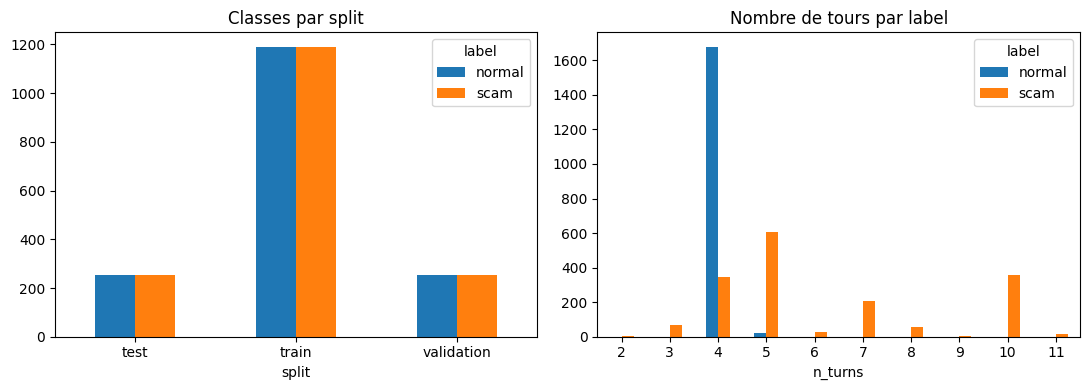

Rapport écrit : C:\Users\chern\Desktop\vishing-detection-1\reports\audit_vish_darija.md


In [28]:
import matplotlib.pyplot as plt

REP = Path("../reports")
(REP / "figures").mkdir(parents=True, exist_ok=True)

# --- Figures ---
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
pd.crosstab(man["split"], man["label"]).plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Classes par split")
pd.crosstab(m["n_turns"], m["label"]).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Nombre de tours par label")
plt.tight_layout()
plt.savefig(REP / "figures" / "classes_et_tours.png", dpi=150)
plt.show()

# --- Chiffres du rapport ---
test = m[m["split"] == "test"]
acc_turns = ((test["n_turns"] > 4).astype(int) == test["y"]).mean()
acc_dur = ((test["duration_sec"] > 21).astype(int) == test["y"]).mean()
ct = pd.crosstab(man["split"], man["label"])
ar_ok = (turns["ar_chars"] > 0).mean()
la_ok = (turns["la_chars"] > 0).mean()
n_hard = int(df["hard_scam"].sum())

report = f"""# Audit du corpus VISH-DARIJA-TTS (DS04)

Source : https://zenodo.org/records/20039126 (v1, licence CC-BY-4.0). Corpus **synthétique** (voix TTS générées).

## 1. Volumétrie
- {len(man)} fichiers audio propres ({man['duration_sec'].sum()/3600:.1f} h, {man['file_size_bytes'].sum()/1e9:.2f} Go) et {len(nz)} variantes bruitées (3 par fichier : SNR 20, 10 et 5 dB).
- {len(turns)} tours de parole, avec texte latin et texte arabe alignés.
- Identifiant fiable : `dataset_uid`. Le `scenario_id` seul n'est pas unique entre classes (normal_0103 et scam_0103 partagent le même).

## 2. Langues
- Darija marocaine, en écriture latine ({la_ok:.1%} des tours ont du texte latin) et arabe ({ar_ok:.1%} ont du texte arabe).
- Les voix sont générées avec le code de langue `ar-EG` (arabe égyptien) : accent éloigné de la darija réelle.

## 3. Labels et déséquilibre des classes
- Équilibre parfait : 1700 scam / 1700 normal, et identique dans chaque split.

{ct.to_markdown()}

- Aucun `dataset_uid` n'apparaît dans plusieurs splits. Les variantes bruitées restent dans le split de leur fichier propre.

## 4. Qualité audio
- Tous les fichiers sont lisibles, en 24 kHz, mono, 16 bits. Aucun doublon de hash.
- Vérification directe sur 300 fichiers : formats et durées conformes au manifest, aucun écrêtage, niveau sonore identique entre classes (AUC du volume : 0,47).
- Les 10 200 variantes bruitées sont équilibrées par classe et par niveau de SNR.

## 5. Raccourcis dans les données (risque de surévaluation)
| Règle triviale | Accuracy sur test |
|---|---|
| Classe majoritaire | 50 % |
| Durée > 21 s = scam | {acc_dur:.1%} |
| Nombre de tours > 4 = scam | {acc_turns:.1%} |

- Les appels normaux ont presque tous 4 tours. À nombre de tours égal, la durée ne sépare plus les classes (AUC 0,52).
- **{n_hard} scams « difficiles »** (4 tours, sans demande sensible) : ils ressemblent aux appels normaux par la structure.
- Colonnes qui donnent directement le label, à ne jamais utiliser comme features : `speaker_role`, `gender`, `contains_sensitive_request`, `request_type`, `persuasion_strategy`. Par précaution : `attack_type`, `requested_asset`, `impersonated_entity`, `victim_role`, `risk_level`.

## 6. Qualité du texte
- {len(cq)} lignes sont marquées `needs_manual_review` : le détecteur de l'auteur signale tout texte contenant un `?`. Ce sont des questions légitimes (faux positifs), non des caractères détruits.
- Exception réelle : 6 textes arabes (scams 324 et 333, tours 0 à 2) sont remplacés par des `?`.

## 7. Limites
- Données synthétiques : pas de garantie de généralisation à de vrais appels.
- Une seule voix TTS (même modèle pour les deux classes) : possible sur-apprentissage du style de voix.
- Les splits fournis sont utilisés tels quels.

## 8. Protocole d'évaluation recommandé
1. Baseline obligatoire : règle sur le nombre de tours (et sur la durée).
2. Métriques globales et sur le sous-ensemble des scams difficiles.
3. Résultats par nombre de tours et par niveau de bruit.
4. Aucune colonne d'annotation du scénario en entrée du modèle.
"""
(REP / "audit_vish_darija.md").write_text(report, encoding="utf-8")
print("Rapport écrit :", (REP / "audit_vish_darija.md").resolve())